In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

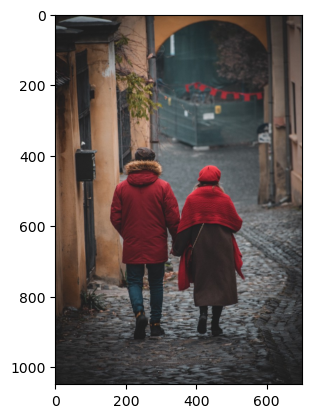

In [2]:
image = cv2.imread("/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/images/PopEffects.jpeg")
plt.imshow(image[..., ::-1])

In [ ]:
def draw_circle(event, x, y, flags, param):
    global img

    if event == cv2.EVENT_LBUTTONDOWN:

        # Extract one pixel
        bgr = img[y:y+1, x:x+1, :]

        print(f"BGR of ({y}, {x}): {bgr[0, 0]}")

        # Convert that pixel from BGR to HSV
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)

        print(f"HSV of ({y}, {x}): {hsv[0, 0]}")

        # Draw a circle at mouse position
        cv2.circle(img, (x, y), 5, (0, 255, 0), 2)


img = cv2.imread(
    "/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/images/PopEffects.jpeg"
)

cv2.namedWindow("image")
cv2.setMouseCallback("image", draw_circle)

while True:
    cv2.imshow("image", img)

    if cv2.waitKey(25) & 0xFF == 27:
        break

cv2.destroyAllWindows()

In [3]:
def pop_effect(image, lower, upper):

    img = image.copy()

    # Convert BGR image to HSV color space
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Convert original image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Create a mask using the color range
    mask = cv2.inRange(hsv, lower, upper)

    # Create inverse mask
    mask_inv = cv2.bitwise_not(mask)

    # Keep only the selected color region
    res = cv2.bitwise_and(img, img, mask=mask)

    # Keep only the background region from the grayscale image
    background = cv2.bitwise_and(gray, gray, mask=mask_inv)

    # Convert grayscale background to a 3-channel image
    background = cv2.cvtColor(background, cv2.COLOR_GRAY2BGR)

    # Combine the colored region and grayscale background
    return cv2.add(res, background)

In [4]:
def pop_effect_call(event, x, y, flags, param, crange=10):
    global img, new_image

    if event == cv2.EVENT_LBUTTONDOWN:

        # Convert BGR image to HSV
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        # Get HSV value of the clicked pixel
        h, s, v = hsv[y, x, :]

        # Convert H to integer to avoid uint8 underflow/overflow
        h = int(h)

        # Create lower and upper bounds for Hue
        h_low = max(0, h - crange)
        h_high = min(179, h + crange)

        lower = np.array([h_low, 50, 50])
        upper = np.array([h_high, 255, 255])

        # Apply pop effect
        new_image = pop_effect(img, lower, upper)

        # Show result
        cv2.imshow("result", new_image)


img = cv2.imread(
    "/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/images/PopEffects.jpeg"
)

cv2.namedWindow("image")
cv2.setMouseCallback("image", pop_effect_call)

while True:
    cv2.imshow("image", img)

    if cv2.waitKey(25) & 0xFF == 27:
        break

cv2.destroyAllWindows()

QFontDatabase: Cannot find font directory /home/mohammadjavad/anaconda3/envs/gnn_env/lib/python3.11/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/mohammadjavad/anaconda3/envs/gnn_env/lib/python3.11/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/mohammadjavad/anaconda3/envs/gnn_env/lib/python3.11/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/mohammadjavad/anaconda3/envs/gnn_env/lib/python3.11/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to font